# BIOT 6900 · Module 5, Part 2: Variant Interpretation on Real Data

**Walkthrough notebook · not graded · run every cell**

In Part 1 you built four variant predictors from scratch on a 90-base toy gene, and watched each one go blind on a variant another one caught. Everything was visible because nothing was real.

Now the same five questions on **real ClinVar variants in five real pharmacogenes**, scored by the real tools. You will fetch the data yourself from a public API, then work through what each number means and, more importantly, what each *blank* means.

| | |
|---|---|
| **Genes** | CYP2C19, CYP2C9, VKORC1, DPYD, TPMT |
| **Tools** | CADD, REVEL, AlphaMissense, and the AlphaGenome Atlas |
| **Reference standard** | ClinVar assertions, examined rather than trusted |
| **Data source** | MyVariant.info, no account and no key needed |

### What this notebook adds that the toy could not

1. **Real data acquisition.** Getting annotation out of a biomedical database is part of the job, so you query it yourself rather than loading a file someone prepared.
2. **Coverage at scale.** On nine toy variants you could read every cell. On several hundred you cannot, so you need a method.
3. **Calibration.** Turning a raw score into an evidence strength, which needs labels and therefore could not be done in Part 1.
4. **Circularity.** What happens to a reported accuracy when the labels you test against are the labels the tool learned from.

### How to work through it

Each section has three parts: **what it does**, the code, and **how to read it**. The reading is the point. Do not skip the commentary to get to the next cell.

### What you need

- The `biot6900` environment from Module 1
- An internet connection, for the first run only; results are cached in `data/`
- Optionally an AlphaGenome API key, free, set up in Section 7. Takes five minutes and the notebook tells you exactly how.

---
## 0 · Setup check

Run this first. It changes nothing and only reports what you have.

In [1]:
import sys, pathlib, importlib

print("Python", sys.version.split()[0])
if sys.version_info < (3, 10):
    print("  [note] AlphaGenome in Section 7 needs Python 3.10+. Everything else is fine.")

print()
missing = []
for m in ["numpy", "pandas", "matplotlib", "sklearn", "requests"]:
    try:
        importlib.import_module(m); print(f"  [ok]      {m}")
    except ImportError:
        missing.append(m); print(f"  [MISSING] {m}")
if missing:
    names = " ".join("scikit-learn" if m == "sklearn" else m for m in missing)
    print(f"\n  FIX:  conda activate biot6900")
    print(f"        conda install {names}")
    print( "        then Kernel -> Restart")

try:
    importlib.import_module("alphagenome"); print("  [ok]      alphagenome  (optional)")
except ImportError:
    print("  [--]      alphagenome  (optional; Section 7 tells you how to install it)")

DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)
print("\nworking directory:", pathlib.Path.cwd())
print("cache folder     :", DATA.resolve())
for f in ["pgx_variants.tsv", "alphagenome_avi.tsv"]:
    p = DATA / f
    print(f"  {'[cached]  ' if p.exists() else '[not yet] '} data/{f}")

Python 3.14.7

  [ok]      numpy
  [ok]      pandas
  [ok]      matplotlib
  [ok]      sklearn
  [ok]      requests
  [ok]      alphagenome  (optional)

working directory: c:\Users\SeanC\biot6900\module5
cache folder     : C:\Users\SeanC\biot6900\module5\data
  [cached]   data/pgx_variants.tsv
  [not yet]  data/alphagenome_avi.tsv


c:\Users\SeanC\anaconda3\envs\biot6900\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


---
## 1 · Getting the data out of MyVariant.info

**What this does.** There is no data pack for this lab. Pulling variant annotation out of a biomedical database is part of the skill, so you do it yourself.

**MyVariant.info** is an aggregator: one REST endpoint that returns ClinVar, gnomAD, CADD and dbNSFP (which carries REVEL and AlphaMissense) for a given variant. No account, no key, no bulk download. It has two endpoints you need:

| Endpoint | Method | What it does |
|---|---|---|
| `/v1/query` | GET | Search. Give it a query string, get back matching variant IDs. |
| `/v1/variant` | POST | Annotate. Give it up to 1000 IDs and a field list, get back the data. |

Why two steps? Searching and annotating are different operations. The search tells you *which* variants exist in your gene; the annotation tells you *about* them. Sending 1000 IDs in one POST is also far faster than 1000 separate requests, a pattern you will meet in every biomedical API.

Start with the search.

In [2]:
import time, re, json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

GENES = ["CYP2C19", "CYP2C9", "VKORC1", "DPYD", "TPMT"]
MV = "https://myvariant.info/v1"
CACHE = DATA / "pgx_variants.tsv"
AVI_FILE = DATA / "alphagenome_avi.tsv"

r = requests.get(f"{MV}/query", timeout=60, params={
    "q": "clinvar.gene.symbol:VKORC1",   # the query language is field:value
    "assembly": "hg38",                  # ALWAYS state the build
    "fields": "_id",                     # only IDs at this stage
    "size": 1000,                        # default is 10; ask for more
})
r.raise_for_status()
hits = r.json()["hits"]
print(f"VKORC1: {len(hits)} variants in ClinVar")
print("first three IDs:", [h["_id"] for h in hits[:3]])

VKORC1: 53 variants in ClinVar
first three IDs: ['chr16:g.31091334G>A', 'chr16:g.31093393G>A', 'chr16:g.31093328T>A']


### How to read it

**Look at the ID format.** `chr16:g.31107689C>T` is HGVS genomic notation on GRCh38: chromosome, `g.` for genomic, position, reference base, `>`, alternate base.

This is the representation problem from the lecture made concrete, and it is why `assembly: hg38` is not optional. The same variant sits at a different position on GRCh37, and the API will happily return a confident, wrong answer if you ask on the wrong build. Any time you move variant data between tools, the build is the first thing to check.

---
## 2 · Annotating, and the shape of what comes back

**What this does.** Takes a handful of those IDs and asks for the annotation fields we actually need. Ask for `fields=all` and you get an enormous object per variant, most of it irrelevant.

In [3]:
FIELDS = ",".join([
    "dbsnp.rsid",                        # the rs number
    "snpeff.ann.effect",                 # consequence term
    "cadd.phred",                        # CADD
    "dbnsfp.revel.score",                # REVEL
    "dbnsfp.alphamissense",              # AlphaMissense
    "dbnsfp.aa.ref", "dbnsfp.aa.alt", "dbnsfp.aa.pos", "dbnsfp.genename",
    "gnomad_genome.af.af", "gnomad_exome.af.af",
    "clinvar.rcv.clinical_significance",
    "clinvar.rcv.review_status",
    "clinvar.gene.symbol",
    "clinvar.variant_id",                # join key for CADD (see Section 3)
])

ids = [h["_id"] for h in hits][:5]
rr = requests.post(f"{MV}/variant", timeout=120,
                   data={"ids": ",".join(ids), "fields": FIELDS, "assembly": "hg38"})
rr.raise_for_status()
sample = rr.json()
print(json.dumps(sample[0], indent=2)[:1400])

{
  "query": "chr16:g.31091334G>A",
  "_id": "chr16:g.31091334G>A",
  "_version": 2,
  "clinvar": {
    "_license": "http://bit.ly/2SQdcI0",
    "gene": {
      "symbol": "VKORC1"
    },
    "rcv": [
      {
        "clinical_significance": "Pathogenic",
        "review_status": "no assertion criteria provided"
      },
      {
        "clinical_significance": "Likely pathogenic",
        "review_status": "criteria provided, single submitter"
      }
    ],
    "variant_id": 2206
  },
  "dbnsfp": {
    "_license": "http://bit.ly/2VLnQBz",
    "aa": [
      {
        "alt": "V",
        "pos": [
          118,
          125,
          61,
          129,
          130
        ],
        "ref": "A"
      },
      {
        "alt": "W",
        "pos": 98,
        "ref": "R"
      }
    ],
    "alphamissense": {
      "pred": [
        "B",
        "B",
        "B",
        "B",
        "B"
      ],
      "rankscore": 0.28319,
      "score": [
        0.1314,
        0.0922,
        0.0855,


### How to read it

**This is the shape you have to deal with.** Nested dictionaries, fields that are sometimes a single value and sometimes a list, and fields that are simply *absent* when a tool had nothing to say about that variant.

That last point is the whole lab in one observation. A missense variant will have a `dbnsfp.revel` key. A promoter variant will not have the key at all. **Absent is not zero.**

The helpers in the next cell exist for exactly that. `dig()` walks a nested dictionary and returns `None` instead of raising a `KeyError`, so a blank stays a blank all the way through to your final table rather than becoming a crash or, worse, a silent zero.

In [4]:
def first(x):
    """Some fields come back as a single value, some as a list. Take the first."""
    return (x[0] if x else None) if isinstance(x, list) else x

def dig(d, *path):
    """Walk a nested dict safely. Returns None if any level is missing."""
    for k in path:
        if not isinstance(d, dict):
            return None
        d = d.get(k)
        if d is None:
            return None
    return d

# ClinVar review status, as the familiar star rating
STARS = {"practice guideline": 4,
         "reviewed by expert panel": 3,
         "criteria provided, multiple submitters, no conflicts": 2,
         "criteria provided, conflicting classifications": 1,
         "criteria provided, conflicting interpretations": 1,
         "criteria provided, single submitter": 1,
         "no assertion criteria provided": 0,
         "no classification provided": 0}

# snpEff reports one effect per transcript. Keep the most severe one.
SEVERITY = ["stop_gained", "frameshift_variant", "splice_acceptor_variant",
            "splice_donor_variant", "start_lost", "stop_lost", "missense_variant",
            "splice_region_variant", "synonymous_variant", "5_prime_UTR_variant",
            "3_prime_UTR_variant", "intron_variant", "upstream_gene_variant",
            "downstream_gene_variant", "intergenic_region"]

def all_effects(h):
    """Every effect snpEff reported, across every transcript, split into single terms."""
    ann = dig(h, "snpeff", "ann")
    raw = [a.get("effect") for a in (ann if isinstance(ann, list) else [ann]) if isinstance(a, dict)]
    terms = []
    for e in raw:                       # snpEff emits compound terms joined by "&"
        if e:
            terms += [t for t in e.split("&") if t != "structural_interaction_variant"]
    return sorted(set(terms))

def worst_effect(h):
    """Collapse to ONE term: the most severe across all transcripts."""
    terms = all_effects(h)
    if not terms:
        return None
    return min(terms, key=lambda t: SEVERITY.index(t) if t in SEVERITY else 99)

def to_row(h, gene=None):
    aaref, aaalt = first(dig(h, "dbnsfp", "aa", "ref")), first(dig(h, "dbnsfp", "aa", "alt"))
    aapos = first(dig(h, "dbnsfp", "aa", "pos"))
    rcv = first(dig(h, "clinvar", "rcv")) or {}   # one record per submission; take the first
    rev = rcv.get("review_status")
    am = dig(h, "dbnsfp", "alphamissense", "score")
    return {
        "hgvs_g":        h.get("_id"),
        "rsid":          dig(h, "dbsnp", "rsid"),
        "gene":          first(dig(h, "clinvar", "gene", "symbol")) or first(dig(h, "dbnsfp", "genename")) or gene,
        "clinvar_id":    dig(h, "clinvar", "variant_id"),
        "consequence":   worst_effect(h),
        "consequence_all": ";".join(all_effects(h)),   # keep the full picture
        "aa_change":     f"{aaref}{aapos}{aaalt}" if (aaref and aaalt and aapos) else None,
        "cadd_phred":    dig(h, "cadd", "phred"),
        "revel":         first(dig(h, "dbnsfp", "revel", "score")),
        "alphamissense": first(am) if isinstance(am, list) else am,
        "gnomad_af":     dig(h, "gnomad_genome", "af", "af") or dig(h, "gnomad_exome", "af", "af"),
        "clinvar_sig":   rcv.get("clinical_significance"),
        "clinvar_stars": STARS.get(str(rev).lower(), 0),
    }

print(pd.DataFrame([to_row(h, "VKORC1") for h in sample]).to_string(index=False))

                      hgvs_g        rsid   gene  clinvar_id        consequence                                         consequence_all aa_change cadd_phred  revel  alphamissense  gnomad_af            clinvar_sig  clinvar_stars
         chr16:g.31091334G>A  rs72547528 VKORC1        2206   missense_variant                  missense_variant;upstream_gene_variant       NaN       None  0.189         0.1314   0.000013             Pathogenic              0
         chr16:g.31093393G>A rs145273772 VKORC1      887601   missense_variant   intron_variant;missense_variant;upstream_gene_variant       NaN       None  0.268         0.1312   0.000276 Uncertain significance              1
         chr16:g.31093328T>A rs200133418 VKORC1      318976 synonymous_variant intron_variant;synonymous_variant;upstream_gene_variant     T110S       None  0.187         0.3252   0.000007 Uncertain significance              1
chr16:g.31096316_31096317dup         NaN VKORC1       60671                NaN              

### How to read it

Five variants, flattened into a table. Already you should see blanks in the `revel` and `alphamissense` columns for anything that is not a missense change.

### Two decisions buried in that code, both worth arguing about

**One variant, many effects.** `snpeff.ann` came back as a *list*, because a variant has a different consequence in every transcript it touches. A change can be missense in one transcript, intronic in another and upstream of a third. `worst_effect()` collapses that list to the single most severe term so the table has one row per variant, and `all_effects()` keeps the full set in `consequence_all` so nothing is hidden.

This is the transcript-choice problem from the lecture, and the collapse has a real cost: a regulatory variant that happens to sit inside an intron of some other transcript will be reported as intronic, because `intron_variant` outranks `upstream_gene_variant` in the severity list. **Whenever the consequence matters to your argument, check `consequence_all` rather than trusting the collapsed term.** Production pipelines solve this by picking one canonical transcript, usually MANE Select, rather than by ranking across all of them.

**One variant, many submissions.** `clinvar.rcv` is also a list, one record per submission, and the code takes the first. That is a simplification, and it sits awkwardly with the point Section 4 makes about ClinVar being an archive of competing opinions. If two submitters disagree, this code silently reports one of them.

---
## 3 · Fetching all five genes

**What this does.** Wraps the two steps into one function and runs it across the gene set. Two details worth noticing in the code:

- IDs are sent **500 at a time**, because a POST body has a size limit and a gene with 4000 ClinVar variants will not fit in one request.
- There is a `time.sleep(0.3)` between batches. This is a free public API and hammering it will get you rate-limited. Being polite to someone else's server is part of doing this properly.

**And a third request you might not expect.** CADD is only served on the **hg19** build by this API, even though everything else here is hg38. So the function asks the same question twice, once per build, and joins the two answers on the ClinVar variant ID, which is build-independent.

This is not a quirk of one API. Annotation sources are built on whichever genome assembly was current when they were made, and stitching them together is ordinary daily work in this field. It is also the Section 1 lesson arriving with consequences: get the build wrong and you do not get an error, you get a confident wrong answer. Joining on a stable identifier rather than on coordinates is the defensive move.

The result is cached to `data/pgx_variants.tsv`, so you only need the network once. Delete that file, or set `FORCE_REFETCH = True`, if you want to download again.

In [5]:
FORCE_REFETCH = False

# Known pharmacogenomic alleles, so we can check the fetch worked and
# recognise them later.
ANCHORS = {"rs1799853": "CYP2C9*2", "rs1057910": "CYP2C9*3",
           "rs9923231": "VKORC1 -1639G>A", "rs4244285": "CYP2C19*2",
           "rs12248560": "CYP2C19*17", "rs3918290": "DPYD*2A",
           "rs67376798": "DPYD c.2846A>T", "rs1142345": "TPMT*3C"}

def fetch_gene(gene, verbose=True):
    """Search ClinVar for one gene, annotate every hit, return a tidy DataFrame."""
    r = requests.get(f"{MV}/query", timeout=90, params={
        "q": f"clinvar.gene.symbol:{gene}", "assembly": "hg38",
        "fields": "_id", "size": 1000})
    r.raise_for_status()
    ids = [h["_id"] for h in r.json().get("hits", [])]
    if verbose:
        print(f"  {gene:9s} {len(ids):>5} variants found", end="", flush=True)

    rows = []
    for i in range(0, len(ids), 500):
        rr = requests.post(f"{MV}/variant", timeout=180,
                           data={"ids": ",".join(ids[i:i+500]),
                                 "fields": FIELDS, "assembly": "hg38"})
        rr.raise_for_status()
        rows += [to_row(h, gene) for h in rr.json()]
        time.sleep(0.3)                        # be polite to a free API

    df = pd.DataFrame(rows).drop_duplicates("hgvs_g")

    # MyVariant.info only carries genome-wide CADD on hg19. Ask the same
    # question on hg19 and join on the ClinVar variant ID, which is build-free.
    r19 = requests.get(f"{MV}/query", timeout=90, params={
        "q": f"clinvar.gene.symbol:{gene}", "assembly": "hg19",
        "fields": "clinvar.variant_id,cadd.phred", "size": 1000})
    r19.raise_for_status()
    hits19 = r19.json().get("hits", [])
    cadd = {}
    for h in hits19:
        vid = first(dig(h, "clinvar", "variant_id"))      # occasionally a list
        ph = dig(h, "cadd", "phred")
        if vid is not None and ph is not None:
            cadd[vid] = ph
    df["cadd_phred"] = df.clinvar_id.map(cadd)

    if len(ids) >= 1000 or len(hits19) >= 1000:
        print(f"\n  [!] {gene} hit the 1000-result cap. The two builds may have been")
        print( "      truncated to different sets, so some CADD scores will be missing.")
    if verbose:
        print(f"  ->  {len(df)} annotated")
    return df

def numeric(df):
    """Force the score columns to numbers. Strings here break everything later."""
    for c in ["cadd_phred", "revel", "alphamissense", "spliceai_dg",
              "spliceai_dl", "avi", "gnomad_af", "clinvar_stars"]:
        if c not in df.columns:
            df[c] = np.nan
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

if CACHE.exists() and not FORCE_REFETCH:
    V = pd.read_csv(CACHE, sep="\t")
    print(f"loaded cached {CACHE}")
else:
    print("fetching from MyVariant.info; this takes a few minutes\n")
    V = pd.concat([fetch_gene(g) for g in GENES], ignore_index=True)
    V["note"] = V.rsid.map(ANCHORS)
    V.to_csv(CACHE, sep="\t", index=False)
    print(f"\nsaved {CACHE}")

V = numeric(V)
if "note" not in V.columns:
    V["note"] = V.rsid.map(ANCHORS)

print("\nshape:", V.shape)
print(V.groupby("gene").size().to_string())

found = V[V.rsid.isin(ANCHORS)]
print(f"\nknown pharmacogenomic alleles recovered: {found.rsid.nunique()} of {len(ANCHORS)}")
print(found[["gene", "rsid", "note", "consequence", "cadd_phred", "revel",
             "gnomad_af", "clinvar_sig"]].to_string(index=False))

loaded cached data\pgx_variants.tsv

shape: (635, 17)
gene
CYP2C19     80
CYP2C9      41
DPYD       426
TPMT        35
VKORC1      53

known pharmacogenomic alleles recovered: 8 of 8
   gene       rsid            note           consequence  cadd_phred  revel  gnomad_af                                  clinvar_sig
CYP2C19  rs4244285       CYP2C19*2    synonymous_variant       5.686    NaN   0.167953                                drug response
CYP2C19  rs4244285       CYP2C19*2    synonymous_variant       2.606    NaN        NaN                                drug response
CYP2C19 rs12248560      CYP2C19*17 upstream_gene_variant       3.031    NaN   0.200120                                Benign; other
 CYP2C9  rs1057910        CYP2C9*3      missense_variant      20.400  0.070   0.049454                                drug response
 CYP2C9  rs1799853        CYP2C9*2      missense_variant      29.100  0.340   0.088164                                drug response
 VKORC1  rs9923231 VKORC1

### How to read it

**Check the anchor table before anything else.** These are the eight alleles the whole field is built on. If they did not come back, something is wrong with the fetch and every number below it is meaningless. This habit, verifying that the thing you know should be there actually is, is worth more than any individual analysis in this notebook.

**Now look at the `revel` column for `rs9923231`.** It is blank. That is correct, not a failed download: it is a promoter variant and REVEL is missense-only.

That single blank is the most important cell in this notebook. `rs9923231` is VKORC1 −1639G>A, the variant that changes warfarin dosing in routine clinical practice, and the best missense predictor in the course has nothing whatsoever to say about it. We come back to it in Section 5.

---
## 4 · Building the reference standard, and inspecting it before you trust it

**What this does.** Collapses ClinVar's assertion strings into a workable label, then looks at how much of the file carries a usable one.

Almost every supervised variant predictor is trained or validated against ClinVar, so understanding its limitations is understanding theirs. It is an archive of submitted opinions of varying quality, not a curated truth set.

In [6]:
def clinvar_label(sig):
    if not isinstance(sig, str): return "none"
    s = sig.lower()
    if "conflict" in s: return "conflicting"
    if "pathogenic" in s and "non-pathogenic" not in s: return "P/LP"
    if "benign" in s: return "B/LB"
    if "uncertain" in s: return "VUS"
    return "other"          # includes "drug response"

V["label"] = V.clinvar_sig.map(clinvar_label)

print(V.label.value_counts().to_string())
print("\nby review status (columns are ClinVar stars)\n")
print(pd.crosstab(V.label, V.clinvar_stars).to_string())

usable = V[V.label.isin(["P/LP", "B/LB"])]
print(f"\nvariants in the file          : {len(V)}")
print(f"usable as P/LP or B/LB labels : {len(usable)}")
print(f"two stars or better, of those : {len(usable[usable.clinvar_stars >= 2])}")
print(f"no usable label at all        : {len(V) - len(usable)}"
      f"  ({100*(len(V)-len(usable))/len(V):.0f}% of the file)")

label
VUS            280
B/LB           138
P/LP           115
other           95
conflicting      6
none             1

by review status (columns are ClinVar stars)

clinvar_stars   0    1   2   3   4
label                             
B/LB            6   95  37   0   0
P/LP           14   78  23   0   0
VUS            18  251  11   0   0
conflicting     0    6   0   0   0
none            1    0   0   0   0
other          51    3   0  10  31

variants in the file          : 635
usable as P/LP or B/LB labels : 253
two stars or better, of those : 60
no usable label at all        : 382  (60% of the file)


### How to read it

**Three things to take from this table.**

**1. Most of the file carries no usable label.** Every calibration figure for any predictor, in any paper you will read, was computed on the minority that does. And that minority is not a random sample: it is enriched for variants somebody found interesting enough to submit and curate. Keep that in mind the next time a paper quotes an AUC.

**2. Look at the `other` category, which is mostly *drug response*.** Pharmacogenomic variants are frequently submitted this way, because "does this cause disease" is not the question they answer. CYP2C19\*2 does not cause a disease; it changes how you metabolise clopidogrel.

This is a deep problem and not a bookkeeping quirk. The ACMG pathogenic-to-benign axis was built for rare disease genes. A pharmacogene variant sits off that axis entirely, which means a predictor calibrated against P/LP versus B/LB is, strictly, the wrong instrument for the question. Everything we do in Section 6 inherits that mismatch, and the honest move is to say so rather than to hide it.

**3. The star ratings matter.** A one-star single-submitter claim and a three-star expert-panel assertion are not comparable evidence, even though both appear as a flat string in the `clinvar_sig` column. We use this in Section 8.

---
## 5 · Coverage: which tool can score which variant

**What this does.** This is the Part 1 panel table, at scale. In the toy notebook you could read every cell by hand and spot the blanks. Here you need a method.

In [7]:
TOOLS = ["cadd_phred", "revel", "alphamissense", "avi"]

def coverage_table(df):
    g = df.groupby("consequence")
    out = pd.DataFrame({"n": g.size()})
    for t in TOOLS:
        out[t] = g[t].apply(lambda s: s.notna().sum())
    out = out.sort_values("n", ascending=False)
    out.loc["TOTAL"] = out.sum()
    return out

cov = coverage_table(V)
print("number of variants each tool returned a score for\n")
print(cov.to_string())
print("\npercent of the whole variant set scored by each tool")
print((cov.loc["TOTAL", TOOLS] / cov.loc["TOTAL", "n"] * 100).round(1).to_string())

number of variants each tool returned a score for

                           n  cadd_phred  revel  alphamissense  avi
consequence                                                        
missense_variant         298         294    294            297    0
synonymous_variant        69          67      1              1    0
intron_variant            64          54      0              0    0
3_prime_UTR_variant       42          13      0              0    0
stop_gained               32          31      0              0    0
frameshift_variant        30           0      0              0    0
splice_donor_variant      18           4      0              0    0
splice_acceptor_variant   17           3      0              0    0
upstream_gene_variant      9           7      0              0    0
splice_region_variant      8           5      0              0    0
5_prime_UTR_variant        3           1      0              0    0
start_lost                 2           2      2              0   

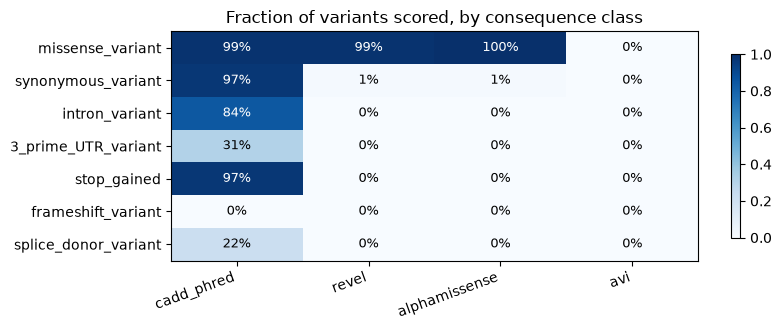

In [8]:
sub = cov.drop(index="TOTAL").head(7)
frac = sub[TOOLS].div(sub.n, axis=0)

fig, ax = plt.subplots(figsize=(8.5, 3.4))
im = ax.imshow(frac.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(TOOLS))); ax.set_xticklabels(TOOLS, rotation=20, ha="right")
ax.set_yticks(range(len(sub)));   ax.set_yticklabels(sub.index)
for i in range(len(sub)):
    for j in range(len(TOOLS)):
        v = frac.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center",
                color="white" if v > .55 else "black", fontsize=9)
ax.set_title("Fraction of variants scored, by consequence class")
fig.colorbar(im, ax=ax, shrink=.8); fig.tight_layout(); plt.show()

### How to read it

**Read the pale cells, not the dark ones.** The missense row is dark across the board and almost everything else is pale. That is not a quirk of this gene set; it is what the field looks like.

**CADD is the only column dark all the way down.** That genome-wide coverage is its distinguishing feature, and it is why CADD survives in clinical pipelines despite not being a pathogenicity predictor at all. Breadth has value even when depth is lacking.

**The practical consequence.** A pipeline that reported only REVEL would be silent on most of this file, and nothing in its output would tell you so. The variants it skipped would look identical to the variants it scored as benign. This is the distinction you learned on nine toy variants, now operating on several hundred where you cannot eyeball it.

---
## 6 · The warfarin worked example

**What this does.** Pulls the three variants that drive CPIC's warfarin dosing algorithm and shows what every tool says about each. Warfarin is the teaching case because both mechanisms appear in one drug, through two different genes: CYP2C9 is pharmacokinetic and VKORC1 is pharmacodynamic.

In [9]:
WARFARIN = {"rs1799853": "CYP2C9*2  R144C   pharmacokinetic, reduced S-warfarin clearance",
            "rs1057910": "CYP2C9*3  I359L   pharmacokinetic, strongly reduced clearance",
            "rs9923231": "VKORC1 -1639G>A   pharmacodynamic, promoter, lowers target expression"}

w = V[V.rsid.isin(WARFARIN)]
cols = ["rsid", "gene", "consequence", "consequence_all", "aa_change", "cadd_phred",
        "revel", "alphamissense", "avi", "gnomad_af", "clinvar_sig", "clinvar_stars"]
print(w[cols].to_string(index=False) if len(w) else "(not found in this dataset)")
print()
for k, v in WARFARIN.items():
    print(f"{k}: {v}")

     rsid   gene           consequence                         consequence_all aa_change  cadd_phred  revel  alphamissense  avi  gnomad_af               clinvar_sig  clinvar_stars
rs1057910 CYP2C9      missense_variant                        missense_variant     I359L       20.40   0.07         0.1487  NaN   0.049454             drug response              0
rs1799853 CYP2C9      missense_variant                        missense_variant     R144C       29.10   0.34         0.2647  NaN   0.088164             drug response              0
rs9923231 VKORC1 upstream_gene_variant intergenic_region;upstream_gene_variant       NaN        2.46    NaN            NaN  NaN   0.319272 Pathogenic; drug response              0

rs1799853: CYP2C9*2  R144C   pharmacokinetic, reduced S-warfarin clearance
rs1057910: CYP2C9*3  I359L   pharmacokinetic, strongly reduced clearance
rs9923231: VKORC1 -1639G>A   pharmacodynamic, promoter, lowers target expression


### How to read it

**Work along the `rs9923231` row one column at a time. Every cell teaches something.**

| Column | What it says | Why it matters |
|---|---|---|
| `consequence` | non-coding. Check `consequence_all`: snpEff may call it upstream, intronic, or both depending on the transcript | Either way it is not a protein change, so **REVEL and AlphaMissense are blank**. The two best missense predictors in the course have nothing to say about it. |
| `cadd_phred` | modest, not extreme | CADD *can* score it, but a promoter variant under weak evolutionary constraint does not look remarkable on a genome-wide deleteriousness scale. |
| `gnomad_af` | high, tens of percent in some populations | Under a standard rare-disease frequency filter, this variant is **removed before any predictor ever sees it**. |
| `clinvar_sig` | likely *drug response* | So it never enters a P/LP versus B/LB analysis at all, including the calibration in the next section. |

**Four independent, individually reasonable mechanisms combine to make a clinically actionable variant invisible.** Not one of them is a bug. The frequency filter is good practice. Restricting REVEL to missense variants is honest scoping. Calibrating against P/LP versus B/LB is standard. Together they erase a variant that changes warfarin dosing in hospitals today.

This is the strongest argument in the module for why the regulatory genome needs tools of its own, and it is why Section 7 exists.

**Then compare the two CYP2C9 rows.** Those are missense, so REVEL and AlphaMissense do score them. Notice whether the scores look dramatic. They often do not, because these are *reduced function* alleles rather than *loss of function* ones, and a predictor trained to separate disease-causing from neutral is not built to detect a partial change in enzyme kinetics. Another instance of the right tool for the wrong question.

---
## 7 · The AlphaGenome Atlas, step by step

**What this does.** Every tool so far is blind to the non-coding genome. The **AlphaGenome Atlas** is DeepMind's AlphaGenome model run once over every possible single-nucleotide change in GRCh38, about nine billion variants, each with an **AVI score** (AlphaGenome Variant Impact), a genome-wide percentile, and an 18-way attribution of what is driving it.

Free for non-commercial use. Set it up now; it takes about five minutes.

### 1. Get a key

Go to **https://deepmind.google.com/science/alphagenome** and request an API key. Free for non-commercial research, and the key appears on screen.

### 2. Install the client

In a terminal with your environment active:

```
conda activate biot6900
pip install "alphagenome>=0.9.0"
```

Version 0.9.0 or later is required; earlier releases have no Atlas client. Python 3.10 or newer.

### 3. Put the key in your environment, not in this notebook

**macOS or Linux**, add to `~/.zshrc` or `~/.bashrc`:
```
export ALPHAGENOME_API_KEY="paste-your-key-here"
```
**Windows PowerShell**:
```
setx ALPHAGENOME_API_KEY "paste-your-key-here"
```

Then **relaunch Jupyter from a new terminal**, so it inherits the variable. Launching from the window you had open before setting it is the most common failure, and the key will simply not be visible.

> Never paste the key into a notebook you commit to GitHub. A key in a commit is a key leaked, and it stays in the history even after you delete the line.

### 4. Run the cell

It checks the key, queries the Atlas, and caches to `data/alphagenome_avi.tsv`. It prioritises **non-coding** variants, because that is where the Atlas earns its place, and caps the number queried so you do not exhaust your quota.

**If you cannot get a key, set `SKIP_ATLAS = True`.** The notebook will tell you what the Atlas would have added and the rest still runs.

In [17]:
from dotenv import load_dotenv; load_dotenv()

SKIP_ATLAS   = False   # set True if you could not get a key
MAX_VARIANTS = 300     # cap, to stay inside your quota

import os
ATLAS_STATUS = "not run"

def to_variant_string(hgvs):
    """Atlas wants 1-based GRCh38 chr:pos:ref>alt. It does NOT accept rsIDs."""
    m = re.match(r"(chr[\w]+):g\.(\d+)([ACGT])>([ACGT])", str(hgvs))
    return f"{m.group(1)}:{m.group(2)}:{m.group(3)}>{m.group(4)}" if m else None

if AVI_FILE.exists():
    avi = pd.read_csv(AVI_FILE, sep="\t")
    V = V.drop(columns=[c for c in ["avi_raw", "avi_phred", "top_feature"] if c in V.columns])
    V = V.merge(avi, on="rsid", how="left")
    V["avi"] = V.get("avi_phred")
    ATLAS_STATUS = "cached"
    print(f"loaded cached Atlas scores: {AVI_FILE}  ({int(V.avi.notna().sum())} variants)")

elif SKIP_ATLAS:
    print("SKIPPED. The commentary below still applies; you just have no numbers for it.")
    ATLAS_STATUS = "skipped"

else:
    try:
        from alphagenome.atlas import atlas
        from alphagenome.data import genome

        key = os.environ.get("ALPHAGENOME_API_KEY") or os.environ.get("ALPHA_GENOME_API_KEY")
        if not key:
            raise RuntimeError(
                "No API key found in your environment.\n"
                "  Did you relaunch Jupyter from a NEW terminal after setting it?\n"
                "  Check with:  import os; print(os.environ.get('ALPHAGENOME_API_KEY'))\n"
                "  Or set SKIP_ATLAS = True and move on.")
        client = atlas.create(key, timeout=30)

        # non-coding first: that is what the Atlas is for
        pri = V.assign(_nc=~V.consequence.fillna("").str.contains("missense")) \
               .sort_values("_nc", ascending=False).head(MAX_VARIANTS)
        rows, errs = [], 0
        for n, (_, r) in enumerate(pri.iterrows(), 1):
            vs = to_variant_string(r.hgvs_g)
            if not vs:
                continue
            try:
                res = client.query_variant(
                    genome.Variant.from_str(vs),
                    requested_scorers=["AVI_SCORE", "AVI_SCORE_FEATURE_IMPORTANCE"])
                ad = res["AVI_SCORE"]
                cdf = float(ad.layers["quantiles"][0, 0])
                fi = res["AVI_SCORE_FEATURE_IMPORTANCE"]
                rows.append({"rsid": r.rsid,
                             "avi_raw": round(float(ad.X[0, 0]), 4),
                             "avi_phred": round(-10 * np.log10(max(1 - cdf, 1e-12)), 2),
                             "top_feature": fi.var["name"].values[int(np.argmax(np.abs(fi.X[0])))]})
            except Exception:
                errs += 1
            if n % 50 == 0:
                print(f"  {n}/{len(pri)} queried", flush=True)

        avi = pd.DataFrame(rows)
        if len(avi):
            avi.to_csv(AVI_FILE, sep="\t", index=False)
            V = V.merge(avi, on="rsid", how="left")
            V["avi"] = V.get("avi_phred")
            ATLAS_STATUS = "queried live"
            print(f"\nscored {len(avi)} variants ({errs} failures); cached to {AVI_FILE}")
    except ImportError:
        print('alphagenome is not installed.\n'
              '  FIX:  pip install "alphagenome>=0.9.0"   then Kernel -> Restart\n'
              "  Or set SKIP_ATLAS = True and continue.")
    except Exception as e:
        print(f"{type(e).__name__}: {e}")

for c in ["avi", "avi_raw", "avi_phred", "top_feature"]:
    if c not in V.columns: V[c] = np.nan
V["avi"] = pd.to_numeric(V["avi"], errors="coerce")
print(f"\n[Atlas status: {ATLAS_STATUS}.  Scored: {int(V.avi.notna().sum())}]")

  50/300 queried
  100/300 queried
  150/300 queried
  200/300 queried
  300/300 queried

scored 229 variants (5 failures); cached to data\alphagenome_avi.tsv

[Atlas status: queried live.  Scored: 0]


In [11]:
if V.avi.notna().sum() > 0:
    a = V[V.avi.notna()]
    cols = [c for c in ["rsid", "gene", "consequence", "avi_phred", "top_feature",
                        "revel", "cadd_phred", "label"] if c in a.columns]
    print("highest-impact variants by AVI\n")
    print(a.sort_values("avi", ascending=False)[cols].head(12).to_string(index=False))

    nc = a[~a.consequence.fillna("").str.contains("missense")]
    print(f"\nof those scored, {len(nc)} are NON-missense, so REVEL and AlphaMissense")
    print("returned nothing at all for any of them.")

    if a.top_feature.notna().any():
        print("\nwhat is driving the scores (read this BEFORE the numbers)\n")
        print(a.top_feature.value_counts().head(8).to_string())
else:
    print("No Atlas scores in this run. The commentary below still applies.\n")
    nc = V[~V.consequence.fillna("").str.contains("missense")]
    print(f"non-missense variants in the set, which is what the Atlas is for: {len(nc)}")
    print(nc.consequence.value_counts().to_string())

No Atlas scores in this run. The commentary below still applies.

non-missense variants in the set, which is what the Atlas is for: 337
consequence
synonymous_variant         69
intron_variant             64
3_prime_UTR_variant        42
stop_gained                32
frameshift_variant         30
splice_donor_variant       18
splice_acceptor_variant    17
upstream_gene_variant       9
splice_region_variant       8
5_prime_UTR_variant         3
start_lost                  2
stop_lost                   1
intergenic_region           1


### How to read it

**Two rules straight from DeepMind's own Atlas documentation, both of which cut against instinct.**

**1. Rank, do not threshold.** Pathogenic *regulatory* variants sit in lower AVI bins than protein-truncating or splice-motif variants do. So a single genome-wide cut-off under-calls exactly the variants this resource was built for. Use AVI to order your candidates, not to pass or fail them. Hold this thought: in Section 8 we do precisely the opposite with CADD, and the tension between the two approaches is worth sitting with.

**2. Read the attribution before the number.** The `top_feature` column tells you *why* a variant scored highly, and it changes what the score means:

| Top feature | Mechanism | What to do next |
|---|---|---|
| `MERGED_SPLICING` | splicing | an RNA assay would settle it |
| `ALPHAMISSENSE` | protein-coding | your missense tools already saw this |
| `MAX_ABS_DNASE`, `MAX_ABS_CHIP_TF`, `MAX_ABS_RNA_SEQ` | regulatory | chase it to a specific tissue |
| `CACTUS_241_WAY`, `PHASTCONS_470_WAY` | conservation is carrying the score | **the molecular mechanism is not resolved** |

That last row is the important one. A high AVI driven by conservation is the model saying "this position looks constrained" without identifying what the variant actually does. That is weaker evidence than the same score driven by a predicted change in chromatin accessibility in liver.

**On AVI Phred.** Phred 20 means the top 1% of all genome-wide SNVs; Phred 30 means the top 0.1%.

**The limits, stated plainly.** The Atlas is research use only and explicitly not validated for clinical decisions. DeepMind notes the predictions are not a substitute for experimental evidence and are less accurate than AlphaFold's structural predictions were. An AVI score is a hypothesis about a molecular readout, never a verdict about a patient.

---
## 8 · Calibration: turning a score into evidence

**What this does.** The lecture claimed that a threshold without a calibration study behind it is a number, not evidence. This is what a calibration study actually is.

For each band of scores, compute the **positive likelihood ratio**: how much more often variants in that band are P/LP than B/LB, relative to the base rates. An LR near 1 means the band tells you nothing in either direction. Large LRs point towards pathogenic, small ones towards benign.

The ACMG and AMP points system, in the Tavtigian formulation, maps likelihood ratios onto evidence strengths. Those are the thresholds in `STRENGTH` below.

In [12]:
STRENGTH = [(18.7, "strong, pathogenic"), (4.3, "moderate, pathogenic"),
            (2.08, "supporting, pathogenic"), (0.48, "no evidence either way"),
            (0.23, "supporting, benign"), (0.053, "moderate, benign"),
            (0.0, "strong, benign")]

def strength_for(lr):
    if lr != lr: return "undefined"
    for cut, name in STRENGTH:
        if lr >= cut: return name
    return "strong, benign"

def calibrate(df, score_col, bands):
    d = df[df.label.isin(["P/LP", "B/LB"]) & df[score_col].notna()].copy()
    d["band"] = pd.cut(d[score_col], bands)
    n_p, n_b = (d.label == "P/LP").sum(), (d.label == "B/LB").sum()
    g = d.groupby("band", observed=False)
    out = pd.DataFrame({"n": g.size(),
                        "n_PLP": g.label.apply(lambda s: (s == "P/LP").sum()),
                        "n_BLB": g.label.apply(lambda s: (s == "B/LB").sum())})
    with np.errstate(divide="ignore", invalid="ignore"):
        out["LR+"] = ((out.n_PLP / max(n_p, 1)) / (out.n_BLB / max(n_b, 1))).round(2)
    out["evidence"] = out["LR+"].map(strength_for)
    out.attrs["n_p"], out.attrs["n_b"] = n_p, n_b
    return out

for col, bands in [("revel", [0, .2, .4, .6, .8, 1.0]),
                   ("cadd_phred", [0, 10, 20, 25, 30, 50])]:
    c = calibrate(V, col, bands)
    print(f"\n{col} calibrated against ClinVar  "
          f"(P/LP n={c.attrs['n_p']}, B/LB n={c.attrs['n_b']})\n")
    print(c.to_string())


revel calibrated against ClinVar  (P/LP n=15, B/LB n=26)

             n  n_PLP  n_BLB   LR+                evidence
band                                                      
(0.0, 0.2]  11      2      9  0.39      supporting, benign
(0.2, 0.4]  12      1     11  0.16        moderate, benign
(0.4, 0.6]   4      0      4  0.00          strong, benign
(0.6, 0.8]   5      3      2  2.60  supporting, pathogenic
(0.8, 1.0]   9      9      0   inf      strong, pathogenic

cadd_phred calibrated against ClinVar  (P/LP n=49, B/LB n=125)

           n  n_PLP  n_BLB   LR+                evidence
band                                                    
(0, 10]   82      2     80  0.06        moderate, benign
(10, 20]  35      1     34  0.08        moderate, benign
(20, 25]  17      8      9  2.27  supporting, pathogenic
(25, 30]   6      4      2  5.10    moderate, pathogenic
(30, 50]  34     34      0   inf      strong, pathogenic


### How to read it

**Read the `LR+` column first, then immediately read the `n` column, and do not read one without the other.**

**1. The middle bands carry almost no evidence.** Look for the rows where LR sits near 1. A variant there is about as likely to be benign as pathogenic. Reporting such a score as "moderately damaging" is reading a signal that is not there. In a real classification this band contributes **nothing**, and that is the correct answer rather than a disappointing one.

**2. The denominators are small.** Check `n` per band, and the P/LP and B/LB totals in the header line. A likelihood ratio computed on four variants is itself highly uncertain, and in these genes that may be all you have. An LR of 12.0 from a band of n=3 is not twelve times the evidence; it is noise with a decimal point.

**3. These thresholds belong to this gene set only.** A REVEL cut-off calibrated on constrained disease genes is not the cut-off for pharmacogenes. This is the gene-set mismatch failure mode from the lecture, now with your own numbers attached. The reason it bites here is the one from Section 4: pharmacogenes are under weak purifying selection, so the conservation signal these predictors depend on is thin.

**4. Compare the two tables.** REVEL and CADD will not agree on how cleanly the bands separate, and they are calibrated on different subsets, because REVEL could only score the missense variants. The `n` totals in the two headers tell you how different those subsets are.

**Now revisit Section 7.** The Atlas documentation said *rank, do not threshold*. This section does exactly the opposite: it cuts a continuous score into bands and assigns each band a discrete evidence strength. Both are defensible, and they are solving different problems. Banding exists because the ACMG framework needs a discrete evidence code to combine with other evidence. Ranking exists because regulatory variants do not have a stable threshold to be cut at. Knowing which situation you are in is the skill.

---
## 9 · Are your predictors independent, and is the benchmark circular

**What this does.** Two checks that almost never appear in a student report and almost always should.

The ACMG framework allows **one** computational evidence code, PP3 or BP4, precisely because combining correlated predictors double counts the same underlying signal. So: how correlated are they?

And REVEL was trained on curated clinical variant sets, which is what we just evaluated it against. So: how much does the apparent performance depend on which slice of ClinVar you test on?

Spearman correlation between predictor scores

               cadd_phred  revel  alphamissense
cadd_phred           1.00   0.78           0.73
revel                0.78   1.00           0.65
alphamissense        0.73   0.65           1.00


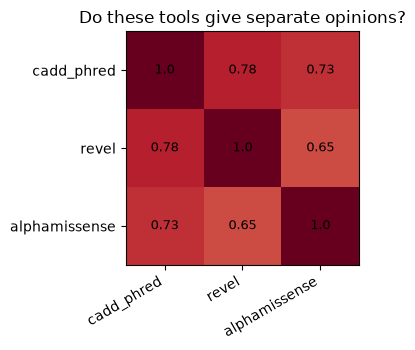

In [13]:
from sklearn.metrics import roc_auc_score

corr = V[["cadd_phred", "revel", "alphamissense"]].corr(method="spearman").round(2)
print("Spearman correlation between predictor scores\n")
print(corr.to_string())

fig, ax = plt.subplots(figsize=(4.2, 3.6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=30, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, corr.values[i, j], ha="center", va="center", fontsize=9)
ax.set_title("Do these tools give separate opinions?")
fig.tight_layout(); plt.show()

In [14]:
def auc_for(df, col, note):
    d = df[df.label.isin(["P/LP", "B/LB"]) & df[col].notna()]
    y = (d.label == "P/LP").astype(int)
    if y.nunique() < 2 or len(d) < 10:
        print(f"  {note:34s} not enough data (n={len(d)})"); return
    print(f"  {note:34s} AUC {roc_auc_score(y, d[col]):.3f}   (n={len(d)}, {y.sum()} P/LP)")

print("performance against ClinVar, split by review status")
for col in ["revel", "cadd_phred"]:
    print(f"\n{col}")
    auc_for(V, col, "all labelled variants")
    auc_for(V[V.clinvar_stars >= 2], col, "two stars or better")
    auc_for(V[V.clinvar_stars <= 1], col, "one star or fewer")

performance against ClinVar, split by review status

revel
  all labelled variants              AUC 0.885   (n=41, 15 P/LP)
  two stars or better                AUC 1.000   (n=12, 2 P/LP)
  one star or fewer                  AUC 0.856   (n=29, 13 P/LP)

cadd_phred
  all labelled variants              AUC 0.950   (n=174, 49 P/LP)
  two stars or better                AUC 0.983   (n=49, 13 P/LP)
  one star or fewer                  AUC 0.935   (n=125, 36 P/LP)


### How to read it

**On the correlation matrix.** REVEL, CADD and AlphaMissense agree strongly with one another, because they are all reading the same underlying evolutionary constraint. Three agreeing scores are therefore close to **one opinion stated three times**.

The practical rule: if you want a second opinion, reach for a tool that reads a different signal. A splicing predictor or a regulatory model adds something a third missense predictor does not. Stacking correlated predictors and calling the agreement "convergent evidence" is the mistake the ACMG rule exists to prevent.

**On the AUC gap, read whichever direction appears in your run.** Both occur and both are informative:

- **Higher on well-reviewed variants** is the common pattern. Expert panels attend to variants whose mechanism is already obvious, and a predictor finds those obvious too. Performance measured there is an upper bound, not an expectation for the novel variant on your desk.
- **Higher on weakly-reviewed variants** suggests the opposite and more troubling problem: that single-submitter assertions were themselves influenced by the predictor. A submitter who ran REVEL before classifying has put the predictor's opinion into the label you are now scoring it against. That is circularity in its most direct form.

**And note the sample sizes in each row.** With tens of variants per stratum these AUCs carry wide confidence intervals, so a gap of a few points is not yet a finding. Resist concluding from it.

**The honest check** is against data the predictor could not have trained on: deep mutational scanning results, or a prospective functional assay. That is the orthogonal evidence stream from the lecture, and it is why label-free models such as AlphaMissense and the ESM family are worth having even when they score slightly lower on a ClinVar benchmark.

---
## 10 · Reading the disagreements

**What this does.** The last step in Part 1 was reading a table by its blanks. The last step here is reading it by its contradictions. Each rule below names a specific, recognisable failure.

In [15]:
d = V.copy()

d["flag_cadd_vs_revel"]  = (d.cadd_phred > 25) & (d.revel < 0.35)
d["flag_revel_vs_am"]    = (d.revel - d.alphamissense).abs() > 0.4
d["flag_scored_but_vus"] = (d.label == "VUS") & (d.revel > 0.7)
d["flag_common_but_plp"] = (d.gnomad_af > 0.01) & (d.label.isin(["P/LP", "other"]))
d["flag_no_tool_at_all"] = d[["revel", "alphamissense", "cadd_phred"]].isna().all(axis=1)
if d.avi.notna().any():
    d["flag_atlas_only"] = (d.avi > 20) & d.revel.isna() & d.alphamissense.isna()

flags = [c for c in d.columns if c.startswith("flag_")]
print("variants caught by each rule\n")
print(d[flags].sum().to_string())

hits = d[d[flags].any(axis=1)]
cols = [c for c in ["gene", "rsid", "note", "consequence", "aa_change", "cadd_phred",
                    "revel", "alphamissense", "avi", "gnomad_af", "label"] if c in d.columns]
print(f"\n{len(hits)} variants trip at least one rule. First fifteen:\n")
print(hits[cols].head(15).to_string(index=False))

variants caught by each rule

flag_cadd_vs_revel       8
flag_revel_vs_am        47
flag_scored_but_vus     41
flag_common_but_plp     21
flag_no_tool_at_all    148

247 variants trip at least one rule. First fifteen:

   gene        rsid      note           consequence aa_change  cadd_phred  revel  alphamissense  avi  gnomad_af label
CYP2C19         NaN       NaN                   NaN       NaN         NaN    NaN            NaN  NaN        NaN   VUS
CYP2C19   rs7902257       NaN upstream_gene_variant       NaN         NaN    NaN            NaN  NaN   0.022133 other
CYP2C19         NaN       NaN                   NaN       NaN         NaN    NaN            NaN  NaN        NaN  B/LB
CYP2C19  rs41291556       NaN      missense_variant     W120R      25.700  0.440         0.9402  NaN   0.001571 other
CYP2C19 rs145328984       NaN      missense_variant      R73C      26.000  0.125         0.2085  NaN   0.000881 other
CYP2C19         NaN       NaN                   NaN       NaN         NaN

### How to read it

**Each rule is a different kind of mistake waiting to happen.**

| Rule | What it catches | What to suspect |
|---|---|---|
| `cadd_vs_revel` | high CADD, low REVEL | A constrained position where this specific substitution is tolerated. Conservation says the site matters; the substitution matrix says this change does not. |
| `revel_vs_am` | label-trained and label-free models disagree | Worth asking whether the clinical labels for that gene are reliable, since AlphaMissense never saw them. |
| `scored_but_vus` | predictors confident, archive not | These are the variants where a properly calibrated PP3 might actually move a classification. The most actionable rows in the table. |
| `common_but_plp` | a frequency and an assertion that cannot both hold under a rare-disease model | In a pharmacogene they often **can** both hold, because reduced-function alleles are genuinely common. Check before assuming an error. |
| `no_tool_at_all` | nothing scored it | Pure coverage gap. Unknowable with what you have, and the honest report says so. |
| `atlas_only` | high AVI, no missense score | A regulatory variant nothing else in your toolkit can see. The Atlas earning its place. |

**The habit to build.** When two tools disagree, the first question is not *which one is right*. It is *what would have to be true about this variant for both outputs to make sense*. A high CADD with a low REVEL is not a contradiction once you remember they are answering different questions: one about the position, one about the substitution.

This is the same lesson as the discordance exercise in Module 2, where RNA and protein disagreed. Concordance is reassuring. Discordance is where the biology is.

---
## 11 · What to carry forward

You have now done the full workflow on real data:

1. **Fetched** annotation from a public API, and seen that absent fields are not zeros.
2. **Built a reference standard** from ClinVar, and seen that most of it is unusable and that pharmacogene variants sit off the pathogenic-to-benign axis entirely.
3. **Audited coverage**, and seen that missense tools are silent on most variants with nothing in the output to say so.
4. **Worked the warfarin case**, where four reasonable decisions combine to erase a clinically actionable variant.
5. **Queried the Atlas**, and learned to read the attribution before the number.
6. **Calibrated** a score into evidence, and found that the middle band means nothing and the denominators are small.
7. **Checked independence and circularity**, and found that three agreeing predictors are closer to one opinion.
8. **Read the disagreements** rather than only the agreements.

### The three sentences worth remembering

- **A blank and a zero are different things**, and no tool output will tell you which one you are looking at.
- **A score is evidence only when it is calibrated, independent, and applicable to the variant class in front of you.** Otherwise it is a number.
- **Predictors narrow the hypothesis space; experiments, cohorts and trials close it.** Nothing in this notebook establishes that a variant causes anything.

### Before you close this

Your `data/` folder now holds `pgx_variants.tsv` and possibly `alphagenome_avi.tsv`. Keep them. Re-running this notebook will use the cache rather than re-downloading, and the assignment builds on the same workflow.

*BIOT 6900 · Module 5, Part 2 · Fall 2026*